# Module G: statistical analysis of the prosthetic-vision pipeline (inputs: Modules B, C and E)
Reads what the other notebooks saved (`pipeline_out_*`: atlas, planner checkpoints, evaluator, `exp1/3/4/probe` json) and adds: **full classification metrics** (accuracy, macro-F1, kappa, MCC, TP/FP/FN/TN per class, confusion matrices, ROC/AUC, calibration), **regression** (psychometric logistic fit of accuracy vs K with K50/K90 and bootstrap CIs, pooled logistic regression with odds ratios, accuracy~fidelity linear regression, robustness slopes), paired McNemar tests with Holm correction, the trap analysis, and an electrode-usage analysis of the layout.

Run order: A (independent), C, B, E, then this notebook. Use the **same settings cell** as in B, C and E.

**Nothing repeats:** nothing is trained here. The evaluator predictions on every planner output are computed once and saved to `OUT/preds_s*.npz`; later runs only load them. `RECOMPUTE = True` forces a refresh (it resets itself).

In [1]:
import os, sys, json, math, time, subprocess, urllib.parse, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw
import yaml, matplotlib.pyplot as plt
from scipy import ndimage
try: import dynaphos
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "dynaphos"]); import dynaphos
from dynaphos.simulator import GaussianSimulator
from dynaphos.utils import Map
from dynaphos.cortex_models import get_cortex_coordinates_grid, get_visual_field_coordinates_from_cortex_full

# ---- keep-in-memory helper: an object is built once per kernel; re-running a cell re-uses it ----
_mem = globals().setdefault("_mem", {})
def once(name, key, build, verbose=True):
    if name in globals() and _mem.get(name) == key:
        if verbose: print(f"[memory] {name}: already loaded, nothing recomputed")
        return globals()[name]
    globals()[name] = build(); _mem[name] = key; return globals()[name]


In [2]:
# ======== shared settings: keep IDENTICAL in the notebooks for modules B, C and E ========
# (they find each other's files through the OUT folder, whose name is built from these values)
QUICK   = True        # True: small end-to-end run (minutes). False: full run (use a GPU)
SOURCE  = "shapes"    # "shapes" = circle/square/triangle/line (plan step A1) | "quickdraw" = stroke drawings
CLASSES = ["circle", "square", "triangle", "line"]    # quickdraw example: ["apple", "bed", "cup", "house", "key", "scissors"]
SIZE, RES, FOV = 256, 256, 10.0     # image size, Dynaphos render size, field of view in degrees
N_ELEC  = 500         # electrodes used (subsampled from a cortical grid inside the field)
I_MAX   = 200.0       # uA. MY CHOICE: brightness ~0.95 here with Dynaphos defaults. Verify against the safety literature.
SEED    = 0           # one seed per run; set 1, 2 and re-run for the other seeds (each seed is cached separately)
N_IMG   = dict(train=60, val=20, test=30) if QUICK else dict(train=400, val=80, test=100)   # drawings per class
dev = "cuda" if torch.cuda.is_available() else "cpu"
NC  = len(CLASSES)
OUT = f"pipeline_out_{'quick' if QUICK else 'full'}_{SOURCE}_{NC}c_{N_ELEC}e_{RES}"; os.makedirs(OUT, exist_ok=True)
KEY = (SEED, N_ELEC, SOURCE, tuple(CLASSES), QUICK, RES, FOV, I_MAX)      # anything cached in memory is rebuilt only if this changes
QD_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/{}.ndjson"
print("device:", dev, "| outputs in", OUT)

# ======== experiment settings (modules B and E) ========
K_LIST = [5, 16, 32] if QUICK else [3, 5, 8, 12, 16, 24, 32, 48, 64]    # K grid for the accuracy-vs-K sweep
K_B2B  = [16] if QUICK else [8, 16, 32]                                  # K values for which the learned planners are trained
KB     = K_B2B[len(K_B2B) // 2]                                          # the K used for ablations / noise / probe
STEPS, BS, EPOCHS = (80, 8, 4) if QUICK else (600, 16, 15)               # B2b steps, batch size, classifier epochs
N_REP  = 2 if QUICK else 4                                               # random-dot samples per training image (T_c and E)
BOOT   = 500 if QUICK else 5000                                          # bootstrap resamples
VARIANTS = {"both": (1., .1, False), "contour_only": (1., 0., False), "task_only": (0., 1., False), "robust": (1., .1, True)}   # (lambda_contour, lambda_task, perturbation training)
def b2a_path(K): return f"{OUT}/B2a_K{K}_s{SEED}.npy"
def b2b_path(v, K): return f"{OUT}/B2b_{v}_K{K}_s{SEED}.pt"


device: cpu | outputs in pipeline_out_quick_shapes_4c_500e_256


In [3]:
def need(mod, pip=None):
    try: __import__(mod)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip or mod])
for m, p in (("pandas", None), ("scipy", None), ("sklearn", "scikit-learn")): need(m, p)
import pandas as pd, warnings
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
warnings.filterwarnings("ignore"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
ARMS = ["R0", "R1", "B1", "B2a", "B2b"]
RECOMPUTE = False               # True = recompute the evaluator predictions on every planner's output (resets itself)


In [4]:
# ---------------------------------------------------------------- Module C: frozen Dynaphos + electrode atlas
PARAMS_YAML = f"""
run: {{resolution: [{RES}, {RES}], view_angle: {FOV}, origin: [0, 0], min_angle: 0.001, fps: 35,
      gpu: {0 if torch.cuda.is_available() else 'null'}, print_stats: false, seed: 42, dtype: float32,
      use_gaussian_lut: false, batch_size: 0}}
display: {{screen_resolution: [1920, 1080], screen_diagonal: 13.3, dist_to_screen: 600}}
sampling: {{sampling_method: receptive_fields, RF_size: 0.5, stimulus_scale: 1.e-4}}
cortex_model: {{model: dipole, k: 17.3, a: 0.75, b: 120, alpha: 0.95, dropout_rate: 0.0, noise_scale: 0.4}}
temporal_dynamics: {{trace_increase_rate: 13.95528162, activation_decay_per_second: 0.00012340980408667956, trace_decay_per_second: 0.99949191}}
size: {{size_equation: sqrt, MD: 0.7, I_half: 40, slope_size: 0.08, current_spread: 675.e-6, radius_to_sigma: 0.5}}
brightness_saturation: {{cps_half: 1.057631326853325e-07, slope_brightness: 19152642.500946816}}
thresholding: {{use_threshold: true, rheobase: 23.9e-6, activation_threshold: 9.141886000943878e-08, activation_threshold_sd: 6.715877869833961e-08}}
default_stim: {{relative_stim_duration: 1, pw_default: 170.e-6, freq_default: 300}}
gabor: {{gabor_filtering: false, gamma: 1.5}}
"""   # = dynaphos config/params.yaml; changed: resolution, view_angle, dropout_rate 0 (dropout is applied at render time). Source: Dynaphos repo defaults.

class Phos:
    """Frozen Dynaphos + electrode atlas. render(I_uA) -> phosphene images; only active electrodes are summed (same maths as sim.__call__)."""
    def __init__(s, n_elec, seed):
        s.P = yaml.safe_load(PARAMS_YAML); rng = np.random.default_rng(seed)
        g = 32 if n_elec <= 1000 else 48
        cc = get_cortex_coordinates_grid(s.P["cortex_model"], g, g, x_max=40)       # g x g electrodes per hemisphere on the cortex
        x, y = get_visual_field_coordinates_from_cortex_full(s.P["cortex_model"], cc, rng).cartesian
        inb = (np.abs(x) < FOV / 2) & (np.abs(y) < FOV / 2)
        s.n_total, s.n_in_field = len(x), int(inb.sum())
        keep = rng.choice(np.flatnonzero(inb), min(n_elec, s.n_in_field), replace=False)
        s.sim = GaussianSimulator(s.P, Map(x=x[keep], y=y[keep]), rng)
        s.N, s.dev = s.sim.num_phosphenes, s.sim.data_kwargs["device"]
        co = s.sim.phosphene_maps.flatten(1).argmin(1).cpu().numpy()                 # pixel index of each phosphene centre
        s.xy = np.c_[x[keep], y[keep]]; s.px = np.c_[co % RES, co // RES]            # visual-field (deg) and pixel (col,row) centres
        p, dp, st = s.P["thresholding"], s.P["default_stim"], s.P["run"]["fps"]
        s.k_cur = st / (dp["pw_default"] * dp["freq_default"] * dp["relative_stim_duration"])   # activation -> current factor
        s.thr0 = s.sim.threshold.get().flatten()
        s.thr = ((p["rheobase"] + s.thr0.cpu().numpy() * s.k_cur) * 1e6 * 1.001 + 1e-3).astype(np.float32)   # uA, lowest current that shows a phosphene
        s.usable = s.thr <= I_MAX                                                    # electrodes that can ever be driven
        s.sim.reset(); s.sim.update(torch.full((s.N,), 128e-6, device=s.dev))        # size atlas at a reference current of 128 uA
        s.sigma_deg = s.sim.sigma.get().flatten().cpu().numpy(); s.sigma_px = s.sigma_deg / FOV * (RES - 1)
        s.ecc = np.linalg.norm(s.xy, axis=1)
        b = s.P["brightness_saturation"]; lvl = .7
        s.i70 = float((p["rheobase"] + (b["cps_half"] + math.log(lvl / (1 - lvl)) / b["slope_brightness"]) * s.k_cur) * 1e6)   # uA for 70 % brightness
        sg = torch.tensor(np.maximum(s.sigma_deg, 1.0 * FOV / (RES - 1)), device=s.dev)[:, None, None]
        W = torch.exp(-.5 * (s.sim.phosphene_maps / sg) ** 2).flatten(1); s.W = W / W.sum(1, keepdim=True)   # Gaussian sampling weights per electrode

    def render(s, I, p_drop=0., sigma_thr=0.):
        """I: (B,N) uA tensor (differentiable) -> (B,1,RES,RES). Optional electrode dropout and log-normal threshold jitter."""
        k = max(int((I > 0).sum(1).max()), 1); idx = I.topk(k, 1).indices; out = []
        for b in range(len(I)):
            if sigma_thr > 0: s.sim.threshold.state = (s.thr0 * torch.exp(sigma_thr * torch.randn_like(s.thr0))).view(-1, 1, 1)
            s.sim.reset(); s.sim.update(I[b].clamp_min(1e-3) * 1e-6)                 # clamp: sqrt(0) has an infinite gradient
            i = idx[b]; sg = s.sim.sigma.get().flatten()[i]; br = s.sim.brightness.get().flatten()[i]
            on = (s.sim.activation.get().flatten() > s.sim.threshold.get().flatten())[i].float() * (I[b][i] > 0).float()
            if p_drop > 0: on = on * (torch.rand(k, device=I.device) > p_drop).float()
            g = torch.exp(-.5 * (s.sim.phosphene_maps[i] / sg.clamp_min(1e-22)[:, None, None]) ** 2)
            out.append((on * br)[:, None, None].mul(g).sum(0))
        s.sim.threshold.state = s.thr0.view(-1, 1, 1)
        return torch.stack(out).clamp(0, 1)[:, None]

def save_atlas(C):
    np.savez(f"{OUT}/atlas_s{SEED}.npz", xy_deg=C.xy, px=C.px, sigma_deg=C.sigma_deg, thr_uA=C.thr, usable=C.usable, i70_uA=C.i70)

def check_atlas(C):
    f = f"{OUT}/atlas_s{SEED}.npz"
    if not os.path.exists(f): print("note: no atlas from the Module C notebook yet (run it once). The layout is rebuilt here from the same settings."); return
    a = np.load(f)
    assert a["xy_deg"].shape == C.xy.shape and np.allclose(a["xy_deg"], C.xy) and np.allclose(a["thr_uA"], C.thr, rtol=1e-3), \
        "this layout differs from the atlas written by the Module C notebook: settings or seed changed. Re-run Module C."
    print("layout matches the atlas written by the Module C notebook")


In [5]:
# ---------------------------------------------------------------- data: stroke drawings -> 256x256 images, contour targets (cached on disk)
def shape_strokes(c, rng):
    n = {"circle": 48, "square": 4, "triangle": 3, "line": 2}[c]
    a = np.linspace(0, 2 * np.pi, n, endpoint=False) + (np.pi / 4 if c == "square" else 0)
    p = np.c_[np.cos(a), np.sin(a) * (rng.uniform(.6, 1) if c != "line" else 0)]
    if c != "line": p = np.vstack([p, p[:1]])                       # close the outline
    t = rng.uniform(0, 2 * np.pi); p = p @ np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return [[list(p[:, 0]), list(p[:, 1])]]

def qd_strokes(name, n):
    f = f"{OUT}/qd_{name}.json"
    if os.path.exists(f) and len(json.load(open(f))) >= n: return json.load(open(f))[:n]
    req = urllib.request.Request(QD_URL.format(urllib.parse.quote(name)), headers={"Range": f"bytes=0-{3000 * n}"})
    raw = urllib.request.urlopen(req, timeout=60).read(3000 * n + 1).decode("utf-8", "ignore").split("\n")[:-1]   # last line may be cut
    out = [d["drawing"] for d in map(json.loads, raw) if d["recognized"]]
    if len(out) < n: raise RuntimeError(f"only {len(out)} drawings for {name}; raise the byte range")
    json.dump(out, open(f, "w")); return out[:n]

def draw(strokes, rng):
    pts = np.concatenate([np.c_[s[0], s[1]] for s in strokes]).astype(float)
    lo, hi = pts.min(0), pts.max(0); span = max((hi - lo).max(), 1e-6)
    ext = rng.uniform(.5, .95) * SIZE                                # object spans 50-95 % of the field
    ctr = SIZE / 2 + rng.uniform(-1, 1, 2) * (SIZE - ext) / 2        # position jitter
    im = Image.new("L", (SIZE, SIZE), 0); d = ImageDraw.Draw(im)
    for s in strokes:
        p = (np.c_[s[0], s[1]] - (lo + hi) / 2) * ext / span + ctr
        if len(p) > 1: d.line(list(map(tuple, p)), fill=255, width=3, joint="curve")
    return np.asarray(im)

def make_split(split, seed):
    off = {"train": 0, "val": N_IMG["train"], "test": N_IMG["train"] + N_IMG["val"]}[split]; n = N_IMG[split]
    X, y = [], []
    for ci, c in enumerate(CLASSES):
        qd = qd_strokes(c, sum(N_IMG.values())) if SOURCE == "quickdraw" else None
        for i in range(n):
            rng = np.random.default_rng([seed, off + i, ci])
            X.append(draw(qd[off + i] if qd else shape_strokes(c, rng), rng)); y.append(ci)
    return np.stack(X), np.array(y)

def gabor_bank(sig=2., lam=4., n=8, ks=15):
    r = torch.arange(ks, dtype=torch.float32) - ks // 2; yy, xx = torch.meshgrid(r, r, indexing="ij"); g = torch.exp(-(xx ** 2 + yy ** 2) / (2 * sig ** 2)); w = []
    for th in np.arange(n) * np.pi / n:
        ph = 2 * np.pi * (xx * np.cos(th) + yy * np.sin(th)) / lam
        ev = g * torch.cos(ph); ev = ev - g * ev.sum() / g.sum()                       # even part with the DC removed
        w += [ev, g * torch.sin(ph)]
    return torch.stack(w)[:, None].to(dev)                                            # (16,1,ks,ks): 8 orientations x (even, odd)

def blur(x, sig):
    r = int(3 * sig) + 1; k = torch.exp(-.5 * (torch.arange(-r, r + 1, device=x.device) / sig) ** 2); k = (k / k.sum()).to(x.dtype)
    return F.conv2d(F.conv2d(x, k.view(1, 1, 1, -1), padding=(0, r)), k.view(1, 1, -1, 1), padding=(r, 0))

def contour_map(x, GB):                                                               # x (B,1,256,256) -> C = sqrt(even^2 + odd^2), max over orientation
    r = F.conv2d(x, GB, padding=GB.shape[-1] // 2).view(len(x), 8, 2, SIZE, SIZE)
    c = r.pow(2).sum(2).sqrt().amax(1, keepdim=True); return c / c.amax((2, 3), keepdim=True).clamp_min(1e-6)

def prep_split(C, X, y, GB):
    """raw uint8 images (n,256,256) -> dict(x image, T blurred contour target, C contour map, score per electrode, y, X)."""
    o = {k: [] for k in ("x", "T", "C", "score")}; r = SIZE // RES
    for i in range(0, len(X), 16):
        x = torch.tensor(X[i:i + 16], dtype=torch.float32, device=dev)[:, None] / 255
        c = F.avg_pool2d(contour_map(x, GB), r); c = c / c.amax((2, 3), keepdim=True).clamp_min(1e-6)
        T = blur(c, 1.5); T = T / T.amax((2, 3), keepdim=True).clamp_min(1e-6)       # blurred contour target
        o["x"].append(F.avg_pool2d(x, r)); o["T"].append(T); o["C"].append(c[:, 0].cpu().numpy()); o["score"].append((c.flatten(1) @ C.W.T).cpu().numpy())
    D = {k: (np.concatenate(v) if k in ("C", "score") else torch.cat(v)) for k, v in o.items()}; D["y"] = y; D["X"] = X; return D

def get_data(C, GB, rebuild=False):
    """Builds the shapes + contour targets ONCE, saves them to OUT/data_s{SEED}.npz, and always loads from that file afterwards."""
    f = f"{OUT}/data_s{SEED}.npz"
    if rebuild or not os.path.exists(f):
        t0 = time.time(); z = {}
        for i, s in enumerate(("train", "val", "test")):
            D = prep_split(C, *make_split(s, 1000 * SEED + i), GB)
            z.update({f"{s}_X": D["X"], f"{s}_y": D["y"], f"{s}_T": D["T"].cpu().numpy().astype(np.float16),
                      f"{s}_C": D["C"].astype(np.float16), f"{s}_score": D["score"].astype(np.float32)})
        np.savez_compressed(f, **z); print(f"data: built and saved to {f} ({time.time() - t0:.0f}s)")
    z = np.load(f); D = {}
    for s in ("train", "val", "test"):
        X = z[f"{s}_X"]
        D[s] = dict(X=X, y=z[f"{s}_y"], x=F.avg_pool2d(torch.tensor(X, dtype=torch.float32, device=dev)[:, None] / 255, SIZE // RES),
                    T=torch.tensor(z[f"{s}_T"].astype(np.float32), device=dev), C=z[f"{s}_C"].astype(np.float32), score=z[f"{s}_score"])
    print(f"data: loaded from {f} | {NC} classes {CLASSES} | images per class train/val/test {N_IMG['train']}/{N_IMG['val']}/{N_IMG['test']}"); return D


In [6]:
# ---------------------------------------------------------------- reference arms, B1, planner network, constraints
def pick(xy, score, K, n0=120, r0=.15, floor=.1):
    """Greedy best-score selection with exclusion radius r0 (deg) and a 10 % floor, then homogeneous thinning to K (paper's density reduction)."""
    if score.max() <= 0: return np.array([], int)
    s = np.where(score >= floor * score.max(), score, -1.); ch = []
    while len(ch) < n0 and s.max() > 0:
        e = int(s.argmax()); ch.append(e); s[np.linalg.norm(xy - xy[e], axis=1) < r0] = -1
    ch = np.array(ch); Dm = np.linalg.norm(xy[ch][:, None] - xy[ch][None], axis=-1); alive = np.ones(len(ch), bool)
    while alive.sum() > K:
        i, j = np.unravel_index(np.where(alive[:, None] & alive[None] & ~np.eye(len(ch), dtype=bool), Dm, np.inf).argmin(), Dm.shape)
        alive[i if score[ch[i]] < score[ch[j]] else j] = False                        # drop the weaker of the closest pair
    return ch[alive]

def plan_b1(C, score, K):
    ch = pick(C.xy, score * C.usable, K); I = np.zeros(C.N, np.float32); I[ch] = np.clip(C.i70, C.thr[ch], I_MAX); return I

def plan_r1(C, K, rng):
    ch = rng.choice(np.flatnonzero(C.usable), K, replace=False); I = np.zeros(C.N, np.float32); I[ch] = rng.uniform(C.thr[ch], I_MAX); return I

def dots(pts, sig=1.5, amp=.9):                                                       # pts (K,2) pixel (col,row) -> Gaussian dot image (idealised scoreboard)
    g = np.arange(RES); d2 = (g[None, :, None] - pts[:, 0, None, None]) ** 2 + (g[None, None, :] - pts[:, 1, None, None]) ** 2
    return np.exp(-.5 * d2 / sig ** 2).sum(0).clip(0, 1).T * amp if len(pts) else np.zeros((RES, RES))

def plan_r0(Cmap, K, rng, thin=True):
    ys, xs = np.nonzero(Cmap > .2); sel = rng.choice(len(xs), min(600, len(xs)), replace=False)
    pts = np.c_[xs[sel], ys[sel]].astype(float); sc = Cmap[ys[sel], xs[sel]]
    ch = pick(pts * FOV / (RES - 1), sc, K) if thin else rng.choice(len(pts), min(K, len(pts)), replace=False)
    return dots(pts[ch])

def topk_st(logits, K):                                                               # hard top-K forward, sigmoid gradient backward
    soft = torch.sigmoid(logits); hard = torch.zeros_like(soft).scatter_(1, logits.topk(K, 1).indices, 1.)
    return hard + soft - soft.detach()

def currents(C, logits, u, K):                                                        # I = m * (thr + (I_max - thr) * sigmoid(u)), always in [thr, I_max]
    thr = torch.tensor(C.thr, device=dev); lg = logits.masked_fill(~torch.tensor(C.usable, device=dev), -1e4)
    return topk_st(lg, K) * (thr + (I_MAX - thr) * torch.sigmoid(u))

class Planner(nn.Module):
    """B2b: small CNN encoder -> features sampled at each electrode's phosphene centre -> shared MLP -> (selection logit, amplitude logit)."""
    def __init__(s, C):
        super().__init__()
        cv = lambda i, o, d: nn.Sequential(nn.Conv2d(i, o, 3, padding=d, dilation=d), nn.ReLU())
        s.enc = nn.Sequential(cv(1, 16, 1), cv(16, 16, 2), cv(16, 16, 4), cv(16, 16, 8), nn.Conv2d(16, 16, 1))
        s.mlp = nn.Sequential(nn.Linear(18, 64), nn.ReLU(), nn.Linear(64, 2))
        s.register_buffer("grid", torch.tensor(C.px / (RES - 1) * 2 - 1, dtype=torch.float32)[None, :, None])
        s.register_buffer("geo", torch.tensor(np.c_[C.sigma_px / 2, C.ecc / FOV], dtype=torch.float32)[None])
    def forward(s, x):
        f = F.grid_sample(s.enc(x), s.grid.expand(len(x), -1, -1, -1), align_corners=True)[..., 0].transpose(1, 2)
        h = s.mlp(torch.cat([f, s.geo.expand(len(x), -1, -1)], -1)); return h[..., 0], h[..., 1]

def run_arm(arm, C, D, K, rng, M, noise=(0., 0.), variant="both"):
    """arm in R0 | R1 | B1 | B2a | B2b -> (phosphene images (n,1,RES,RES), currents or None). M holds the trained B2 models."""
    n = len(D["y"])
    if arm == "R0": return torch.tensor(np.stack([plan_r0(D["C"][b], K, rng) for b in range(n)]), device=dev, dtype=torch.float32)[:, None], None
    if arm == "R1": I = np.stack([plan_r1(C, K, rng) for _ in range(n)])
    elif arm == "B1": I = np.stack([plan_b1(C, D["score"][b], K) for b in range(n)])
    elif arm == "B2a": I = M["tmpl"][K][D["y"]]
    else:
        with torch.no_grad(): I = currents(C, *M["b2b"][(variant, K)](D["x"]), K).cpu().numpy()
    with torch.no_grad(): P = torch.cat([C.render(torch.tensor(I[i:i + 16], device=dev), *noise) for i in range(0, n, 16)])
    return P, I

def fidelity(P, T, tau=2):
    """precision / recall / F-score of phosphene mass versus the contour, tolerance tau px (about one phosphene radius)."""
    Tn = T / T.amax((2, 3), keepdim=True).clamp_min(1e-6); Mk = (Tn > .5).float(); Dl = (F.max_pool2d(Mk, 2 * tau + 1, 1, tau) > 0).float()
    prec = ((P * Dl).sum((1, 2, 3)) / (P.sum((1, 2, 3)) + 1e-6)).cpu().numpy()
    rec = ((Mk * (F.max_pool2d((P > .05).float(), 2 * tau + 1, 1, tau))).sum((1, 2, 3)) / (Mk.sum((1, 2, 3)) + 1e-6)).cpu().numpy()
    return prec, rec, 2 * prec * rec / (prec + rec + 1e-9)

def visible(P): return np.array([ndimage.label(p[0].cpu().numpy() > .05)[1] for p in P])   # distinct phosphene blobs above a brightness criterion
def to_u8(P): return (P.clamp(0, 1) * 255).round().to(torch.uint8)


In [7]:
# ---------------------------------------------------------------- classifiers on sparse-dot images (T_c in module B, E in module E)
def make_cnn():                                                                       # T_c: plain CNN (training classifier used inside B2b's task loss)
    blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(blk(1, 16), blk(16, 32), blk(32, 64), blk(64, 64), blk(64, 64), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, NC))

class Res(nn.Module):
    def __init__(s, i, o, st):
        super().__init__(); s.a = nn.Sequential(nn.Conv2d(i, o, 3, st, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o))
        s.sc = nn.Sequential() if (i == o and st == 1) else nn.Sequential(nn.Conv2d(i, o, 1, st, bias=False), nn.BatchNorm2d(o))
    def forward(s, x): return F.relu(s.a(x) + s.sc(x))

def make_resnet():                                                                    # E: ResNet-style evaluator, different family from A and T_c
    return nn.Sequential(nn.Conv2d(1, 16, 3, 2, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU(), Res(16, 16, 1), Res(16, 32, 2), Res(32, 64, 2), Res(64, 64, 2),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, NC))

def front(P): return blur(P, 1.2) * 4                                                 # fixed front-end for both classifiers: dots -> small blobs

def fit_clf(net, X, y, seed, path, retrain=False):
    """Trains net on uint8 dot images X (n,1,H,W). If `path` exists the saved weights are loaded and NOTHING is trained."""
    if os.path.exists(path) and not retrain: net.load_state_dict(torch.load(path, map_location=dev)); print(f"loaded {path} (no training)"); return net.eval()
    t0 = time.time(); torch.manual_seed(seed); opt = torch.optim.Adam(net.parameters(), 2e-3); n = len(y); yt = torch.tensor(y, device=dev)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=EPOCHS * ((n + 63) // 64))
    for ep in range(EPOCHS):
        net.train(); perm = torch.randperm(n, device=dev)
        for i in range(0, n, 64):
            b = perm[i:i + 64]; loss = F.cross_entropy(net(front(X[b].float() / 255)), yt[b])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        print(f"  epoch {ep + 1}/{EPOCHS} loss {loss.item():.3f}")
    torch.save(net.state_dict(), path); print(f"trained and saved {path} ({time.time() - t0:.0f}s)"); return net.eval()

@torch.no_grad()
def clf_acc(net, X, y, bs=64):
    p = torch.cat([net(front(X[i:i + bs].float() / 255)).argmax(1).cpu() for i in range(0, len(X), bs)]); return (p.numpy() == y).astype(float)

def dot_data(C, D, mode, seed):
    """Classifier training data independent of every planner: 'board' = random dots on the true contour; 'elec' = Dynaphos renders of random contour-adjacent electrodes."""
    rng = np.random.default_rng(seed); X, y = [], []; n = len(D["y"])
    for rep in range(N_REP):
        ims = []
        for b in range(n):
            K = int(rng.integers(3, 65))
            if mode == "board":
                ys, xs = np.nonzero(D["C"][b] > .3); sel = rng.choice(len(xs), min(K, len(xs)), replace=False)
                pts = np.c_[xs[sel], ys[sel]] + rng.normal(0, 1, (len(sel), 2)); pts = pts[rng.random(len(pts)) > rng.uniform(0, .3)]
                ims.append(dots(pts, rng.uniform(1, 2.5), rng.uniform(.6, 1)))
            else:
                sc = D["score"][b] * C.usable; cand = np.flatnonzero(sc > .2 * sc.max()); sel = rng.choice(cand, min(K, len(cand)), replace=False)
                I = np.zeros(C.N, np.float32); I[sel] = rng.uniform(C.thr[sel], I_MAX); ims.append(I)
        if mode == "board": P = np.stack(ims)
        else:
            with torch.no_grad(): P = torch.cat([C.render(torch.tensor(np.stack(ims[i:i + 16]), device=dev), rng.choice([0, .1, .2]), rng.choice([0, .1, .25])) for i in range(0, n, 16)])[:, 0].cpu().numpy()
        X.append((P * 255).astype(np.uint8)); y.append(D["y"])
    return np.concatenate(X), np.concatenate(y)

def get_dots(C, D, mode, split, seed):
    """dot_data with an on-disk cache: generated once, loaded from OUT/dots_*.npz on every later run."""
    f = f"{OUT}/dots_{mode}_{split}_{seed}.npz"
    if not os.path.exists(f):
        t0 = time.time(); X, y = dot_data(C, D, mode, seed); np.savez_compressed(f, X=X, y=y); print(f"dots {mode}/{split}: generated and saved ({time.time() - t0:.0f}s)")
    z = np.load(f); return torch.tensor(z["X"], device=dev)[:, None], z["y"]


### Layout, data, planners and evaluator (loaded from the files written by B, C and E)

In [8]:
C = once("C", KEY, lambda: Phos(N_ELEC, SEED)); check_atlas(C); print(f"{C.N} electrodes, {C.usable.sum()} usable")
GB = once("GB", KEY, gabor_bank, verbose=False)
REBUILD_DATA = False                           # True = regenerate the shapes/contours once (resets itself)
if REBUILD_DATA: _mem.pop("D", None)
D = once("D", KEY, lambda: get_data(C, GB, REBUILD_DATA)); REBUILD_DATA = False
Dtr, Dva, Dte = D["train"], D["val"], D["test"]; print({k: len(v["y"]) for k, v in D.items()}, "images")

# ---------- load the frozen planners saved by the Module B notebook (nothing is trained here) ----------
def load_planners(C):
    M = {"tmpl": {}, "b2b": {}}
    for K in K_B2B:
        if os.path.exists(b2a_path(K)): M["tmpl"][K] = np.load(b2a_path(K))
        for v in VARIANTS:
            if os.path.exists(b2b_path(v, K)):
                net = Planner(C).to(dev); net.load_state_dict(torch.load(b2b_path(v, K), map_location=dev)); M["b2b"][(v, K)] = net.eval()
    assert ("both", KB) in M["b2b"], f"no planner checkpoints found in {OUT}: run the Module B notebook first (with the same settings)"
    print(f"planners loaded: templates K={sorted(M['tmpl'])}, B2b {sorted(M['b2b'])}"); return M
M = once("M", KEY, lambda: load_planners(C))
HAVE = lambda v, K=None: (v, KB if K is None else K) in M["b2b"]


layout matches the atlas written by the Module C notebook
500 electrodes, 498 usable
data: loaded from pipeline_out_quick_shapes_4c_500e_256/data_s0.npz | 4 classes ['circle', 'square', 'triangle', 'line'] | images per class train/val/test 60/20/30
{'train': 240, 'val': 80, 'test': 120} images
planners loaded: templates K=[16], B2b [('both', 16), ('contour_only', 16), ('robust', 16), ('task_only', 16)]


In [9]:
# ---------- E_main: the independent evaluator. Trained once on random-dot images only (never on planner output), then saved. ----------
RETRAIN_EVALUATOR = False       # True = retrain E_main (resets itself to False afterwards)
def build_e():
    Xb, yb = get_dots(C, Dtr, "board", "train", 100 + SEED); Xe, ye = get_dots(C, Dtr, "elec", "train", 200 + SEED)
    return fit_clf(make_resnet().to(dev), torch.cat([Xb, Xe]), np.concatenate([yb, ye]), SEED, f"{OUT}/E_main_s{SEED}.pt", RETRAIN_EVALUATOR)
if RETRAIN_EVALUATOR: _mem.pop("E", None)
E = once("E", KEY, build_e); RETRAIN_EVALUATOR = False
Xbv, ybv = get_dots(C, Dva, "board", "val", 300 + SEED); Xev, yev = get_dots(C, Dva, "elec", "val", 400 + SEED)
print(f"E_main accuracy on held-out random-dot images (report this first, plan 7.1): board {clf_acc(E, Xbv, ybv).mean():.1%} | Dynaphos-elec {clf_acc(E, Xev, yev).mean():.1%}")
Tc = None
if os.path.exists(f"{OUT}/T_c_s{SEED}.pt"):
    Tc = make_cnn().to(dev); Tc.load_state_dict(torch.load(f"{OUT}/T_c_s{SEED}.pt", map_location=dev)); Tc.eval(); print("T_c loaded from Module B (used only for the trap ablation)")


loaded pipeline_out_quick_shapes_4c_500e_256/E_main_s0.pt (no training)
E_main accuracy on held-out random-dot images (report this first, plan 7.1): board 46.2% | Dynaphos-elec 46.2%
T_c loaded from Module B (used only for the trap ablation)


### 1-2. Saved results and evaluator predictions

In [10]:
# ---------- 1. everything Modules B, C and E already saved (nothing is recomputed here) ----------
def jl(name):
    f = f"{OUT}/{name}_s{SEED}.json"; return json.load(open(f)) if os.path.exists(f) else None
exp1, exp3, exp4, probe, crec = jl("exp1"), jl("exp3"), jl("exp4"), jl("probe"), jl("c_record"); atlas = np.load(f"{OUT}/atlas_s{SEED}.npz"); Dt = Dte
print({n: (v is not None) for n, v in dict(exp1=exp1, exp3=exp3, exp4=exp4, probe=probe, c_record=crec).items()}, "| atlas:", list(atlas.files))
assert exp1 is not None, "run the Module E notebook first (Experiment 1 results are needed)"


{'exp1': True, 'exp3': True, 'exp4': True, 'probe': True, 'c_record': True} | atlas: ['xy_deg', 'px', 'sigma_deg', 'thr_uA', 'usable', 'i70_uA']


In [11]:
# ---------- 2. evaluator predictions on every planner's output: computed ONCE, saved to OUT/preds_s*.npz, loaded afterwards ----------
PRED_F = f"{OUT}/preds_s{SEED}.npz"
def compute_preds():
    t0 = time.time(); z = {"y": Dt["y"]}; jobs = []
    for a in ARMS:
        for K in K_LIST:
            if a == "B2a" and K not in M["tmpl"]: continue
            if a == "B2b" and not HAVE("both", K): continue
            jobs.append((a, "both", K, a))
    for v in ("contour_only", "task_only", "robust"):
        if HAVE(v): jobs.append(("B2b", v, KB, f"B2b:{v}"))
    for a, v, K, name in jobs:
        P, I = run_arm(a, C, Dt, K, np.random.default_rng(SEED * 1000 + K), M, variant=v); U = to_u8(P)
        with torch.no_grad():
            z[f"prob|{name}|{K}"] = torch.cat([E(front(U[i:i + 64].float() / 255)).softmax(1).cpu() for i in range(0, len(U), 64)]).numpy()
            if Tc is not None and a == "B2b" and K == KB: z[f"tprob|{name}|{K}"] = torch.cat([Tc(front(U[i:i + 64].float() / 255)).softmax(1).cpu() for i in range(0, len(U), 64)]).numpy()
        z[f"vis|{name}|{K}"] = visible(P)
        if I is not None: z[f"usage|{name}|{K}"] = (I > 0).sum(0); z[f"load|{name}|{K}"] = I.sum(1)
    np.savez_compressed(PRED_F, **z); print(f"predictions computed for {len(jobs)} planner settings in {time.time() - t0:.0f}s -> {PRED_F}")
def get_preds():
    if RECOMPUTE or not os.path.exists(PRED_F): compute_preds()
    else: print("predictions: loaded", PRED_F, "(nothing recomputed)")
    z = np.load(PRED_F); return {k: z[k] for k in z.files}
if RECOMPUTE: _mem.pop("PR", None)
PR = once("PR", KEY, get_preds); RECOMPUTE = False
y = PR["y"]; ITEMS = sorted({(k.split("|")[1], int(k.split("|")[2])) for k in PR if k.startswith("prob|")}, key=lambda t: (ARMS.index(t[0].split(":")[0]), t[1], t[0]))
def prob(name, K): p = PR[f"prob|{name}|{K}"].astype(np.float64); return p / p.sum(1, keepdims=True)
corr = {(n, K): (prob(n, K).argmax(1) == y) for n, K in ITEMS}; Kset = {a: sorted(K for n, K in ITEMS if n == a) for a in ARMS}
print(len(y), "test images |", len(ITEMS), "planner settings:", {a: Kset[a] for a in ARMS}, "| plus ablation variants at K =", KB)
chk = [abs(corr[(a, K)].mean() - exp1[f"{a}|{K}"]["acc"]) for (a, K) in corr if a in ("B1", "B2a", "B2b") and f"{a}|{K}" in exp1]
print(f"consistency with Module E (deterministic arms B1/B2a/B2b): max |accuracy difference| = {max(chk) if chk else float('nan'):.4f} (should be 0)")


predictions: loaded pipeline_out_quick_shapes_4c_500e_256/preds_s0.npz (nothing recomputed)
120 test images | 14 planner settings: {'R0': [5, 16, 32], 'R1': [5, 16, 32], 'B1': [5, 16, 32], 'B2a': [16], 'B2b': [16]} | plus ablation variants at K = 16
consistency with Module E (deterministic arms B1/B2a/B2b): max |accuracy difference| = 0.0000 (should be 0)


### 3. Metrics for every planner setting

In [12]:
# ---------- 3. full classification metrics for every planner setting ----------
def cm_np(yy, pp, n=NC): return np.bincount(np.asarray(yy) * n + np.asarray(pp), minlength=n * n).reshape(n, n)
def macro_f1_cm(cm):
    tp = np.diag(cm); d = 2 * tp + cm.sum(0) - tp + cm.sum(1) - tp; return float(np.mean(np.where(d > 0, 2 * tp / np.maximum(d, 1), 0)))
def ece(pr, yy, bins=10):
    conf, ok = pr.max(1), pr.argmax(1) == yy; e = 0.
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi); e += m.mean() * abs(ok[m].mean() - conf[m].mean()) if m.any() else 0
    return e
def tpfp_table(yy, pp, classes=CLASSES):
    cm = cm_np(yy, pp, len(classes)); tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
    return pd.DataFrame(dict(support=cm.sum(1), TP=tp, FP=fp, FN=fn, TN=tn, precision=tp / np.maximum(tp + fp, 1), recall_TPR=tp / np.maximum(tp + fn, 1), specificity_TNR=tn / np.maximum(tn + fp, 1),
                             FPR=fp / np.maximum(fp + tn, 1), F1=2 * tp / np.maximum(2 * tp + fp + fn, 1)), index=classes)
def plot_cm(ax, cm, classes, title):
    n = cm / np.maximum(cm.sum(1, keepdims=True), 1); ax.imshow(n, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(classes)):
        for j in range(len(classes)): ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="white" if n[i, j] > .5 else "black")
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=7); ax.set_yticklabels(classes, fontsize=7); ax.set_title(title, fontsize=9)
rng = np.random.default_rng(SEED); nb_ = min(BOOT, 500); rows = []
for n, K in ITEMS:
    pr = prob(n, K); p = pr.argmax(1); cm = cm_np(y, p); idx = rng.integers(0, len(y), (nb_, len(y))); bf = np.percentile([macro_f1_cm(cm_np(y[i], p[i])) for i in idx], [2.5, 97.5]); ba = np.percentile([(p[i] == y[i]).mean() for i in idx], [2.5, 97.5])
    rows.append(dict(arm=n, K=K, acc=np.trace(cm) / cm.sum(), acc_lo=ba[0], acc_hi=ba[1], macro_F1=macro_f1_cm(cm), F1_lo=bf[0], F1_hi=bf[1], bal_acc=balanced_accuracy_score(y, p), kappa=cohen_kappa_score(y, p), MCC=matthews_corrcoef(y, p),
                     AUC_ovr=roc_auc_score(y, pr, multi_class="ovr", labels=list(range(NC))), ECE=ece(pr, y), mean_conf=pr.max(1).mean(), visible=PR[f"vis|{n}|{K}"].mean(), top_class_share=np.bincount(p, minlength=NC).max() / len(p)))
MET = pd.DataFrame(rows); MET.to_csv(f"{OUT}/G_metrics_s{SEED}.csv", index=False); print("E_main metrics on every planner output (acc / macro-F1 with 95% bootstrap CIs; AUC one-vs-rest; ECE = calibration error; top_class_share = share of the most predicted class, 1/NC = balanced, 1 = collapse):")
display(MET.round(3))


E_main metrics on every planner output (acc / macro-F1 with 95% bootstrap CIs; AUC one-vs-rest; ECE = calibration error; top_class_share = share of the most predicted class, 1/NC = balanced, 1 = collapse):


,arm,K,acc,acc_lo,acc_hi,macro_F1,F1_lo,F1_hi,bal_acc,kappa,MCC,AUC_ovr,ECE,mean_conf,visible,top_class_share
0,R0,5,0.317,0.233,0.400,0.235,0.163,0.295,0.317,0.089,0.113,0.664,0.040,0.305,5.000,0.675
1,R0,16,0.383,0.292,0.467,0.321,0.248,0.375,0.383,0.178,0.223,0.745,0.085,0.395,15.650,0.700
2,R0,32,0.550,0.458,0.633,0.529,0.450,0.596,0.550,0.400,0.409,0.789,0.142,0.421,26.075,0.392
3,R1,5,0.242,0.158,0.329,0.124,0.079,0.181,0.242,-0.011,-0.031,0.521,0.185,0.423,4.950,0.950
4,R1,16,0.250,0.175,0.325,0.125,0.081,0.170,0.250,0.000,0.000,0.509,0.120,0.370,15.633,0.917
5,R1,32,0.250,0.175,0.333,0.101,0.075,0.126,0.250,0.000,0.000,0.529,0.163,0.413,30.975,0.992
6,B1,5,0.383,0.292,0.467,0.295,0.227,0.357,0.383,0.178,0.204,0.715,0.127,0.323,5.000,0.475
7,B1,16,0.433,0.350,0.517,0.375,0.304,0.439,0.433,0.244,0.292,0.795,0.081,0.377,15.950,0.633
8,B1,32,0.533,0.433,0.629,0.475,0.413,0.536,0.533,0.378,0.414,0.809,0.154,0.382,28.867,0.508
9,B2a,16,0.500,0.408,0.596,0.375,0.349,0.400,0.500,0.333,0.471,0.917,0.383,0.493,12.000,0.750


### 4. Confusion matrices, TP/FP/FN/TN, ROC, calibration

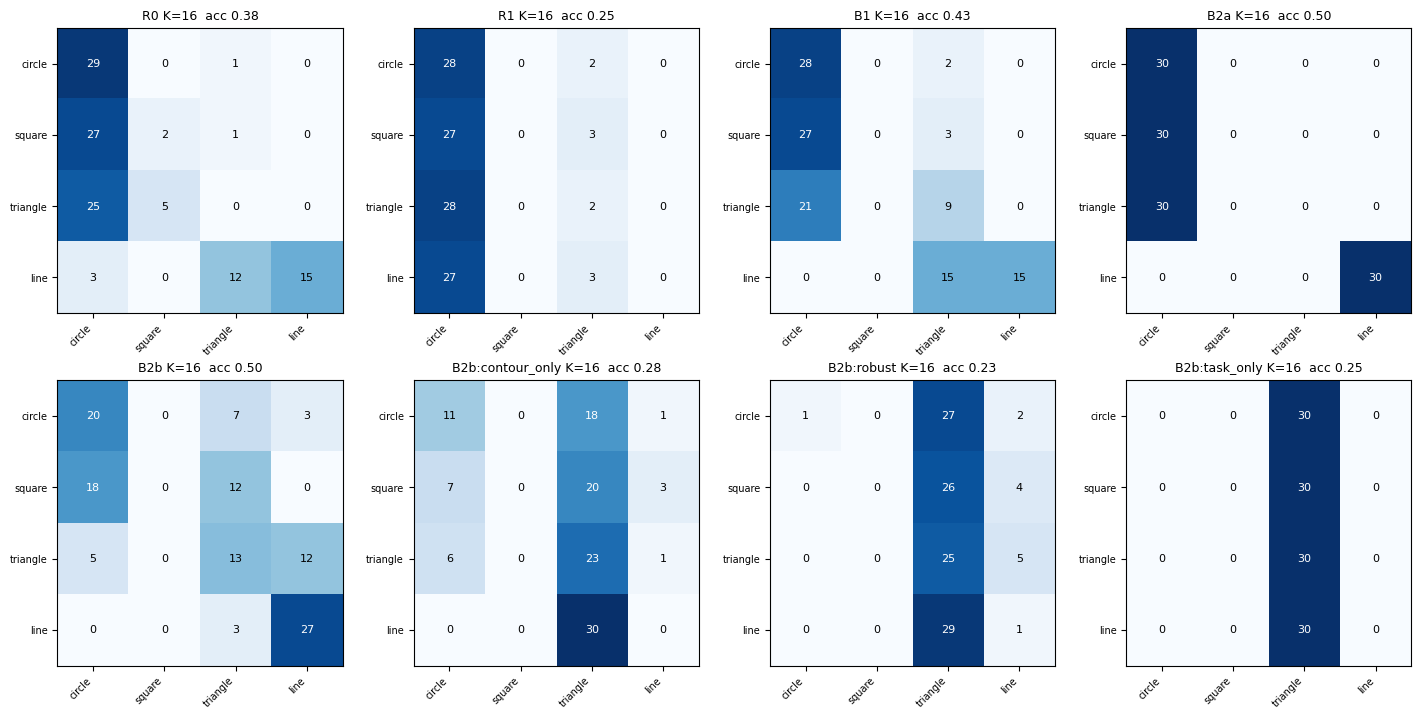


TP / FP / FN / TN per class: B1, K=16


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1
circle,30,28,48,2,42,0.368,0.933,0.467,0.533,0.528
square,30,0,0,30,90,0.000,0.000,1.000,0.000,0.000
triangle,30,9,20,21,70,0.310,0.300,0.778,0.222,0.305
line,30,15,0,15,90,1.000,0.500,1.000,0.000,0.667



TP / FP / FN / TN per class: B2b, K=16


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1
circle,30,20,23,10,67,0.465,0.667,0.744,0.256,0.548
square,30,0,0,30,90,0.000,0.000,1.000,0.000,0.000
triangle,30,13,22,17,68,0.371,0.433,0.756,0.244,0.400
line,30,27,15,3,75,0.643,0.900,0.833,0.167,0.750



TP / FP / FN / TN per class: R1, K=16


,support,TP,FP,FN,TN,precision,recall_TPR,specificity_TNR,FPR,F1
circle,30,28,82,2,8,0.255,0.933,0.089,0.911,0.4
square,30,0,0,30,90,0.000,0.000,1.000,0.000,0.0
triangle,30,2,8,28,82,0.200,0.067,0.911,0.089,0.1
line,30,0,0,30,90,0.000,0.000,1.000,0.000,0.0


per-class true-positive rate (recall) at K=16:


,circle,square,triangle,line
R0,0.97,0.07,0.00,0.50
R1,0.93,0.00,0.07,0.00
B1,0.93,0.00,0.30,0.50
B2a,1.00,0.00,0.00,1.00
B2b,0.67,0.00,0.43,0.90
B2b:contour_only,0.37,0.00,0.77,0.00
B2b:robust,0.03,0.00,0.83,0.03
B2b:task_only,0.00,0.00,1.00,0.00


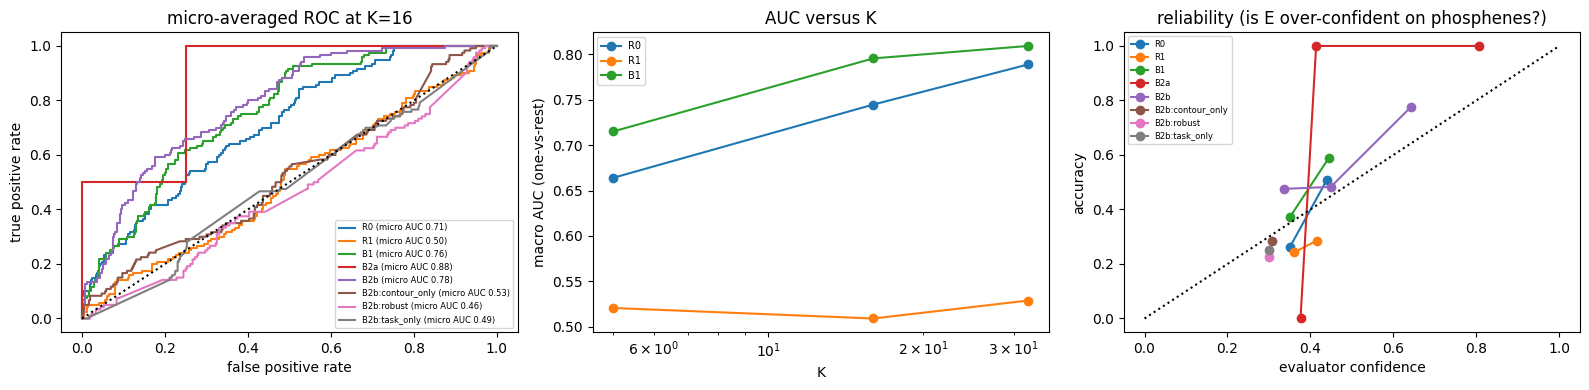

In [13]:
# ---------- 4. confusion matrices and TP / FP / FN / TN at K = KB; ROC and calibration ----------
names = [n for n, K in ITEMS if K == KB]; ncol = 4; nrow = int(np.ceil(len(names) / ncol)); fig, ax = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.6 * nrow), squeeze=False)
for a_, n in zip(ax.ravel(), names): plot_cm(a_, cm_np(y, prob(n, KB).argmax(1)), CLASSES, f"{n} K={KB}  acc {corr[(n, KB)].mean():.2f}")
for a_ in ax.ravel()[len(names):]: a_.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/G_confusion_K{KB}_s{SEED}.png", dpi=110); plt.show()
for n in ("B1", "B2b", "R1"):
    if (n, KB) in corr: print(f"\nTP / FP / FN / TN per class: {n}, K={KB}"); display(tpfp_table(y, prob(n, KB).argmax(1)).round(3))
tpr = pd.DataFrame({f"{n}": tpfp_table(y, prob(n, K).argmax(1)).recall_TPR for n, K in ITEMS if K == KB}); print(f"per-class true-positive rate (recall) at K={KB}:"); display(tpr.round(2).T)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n in names:
    pr = prob(n, KB); ax[0].plot(*roc_curve((y[:, None] == np.arange(NC)).ravel(), pr.ravel())[:2], label=f"{n} (micro AUC {roc_auc_score((y[:, None] == np.arange(NC)).ravel(), pr.ravel()):.2f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title(f"micro-averaged ROC at K={KB}"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].legend(fontsize=6)
for a in ARMS:
    d = MET[MET.arm == a]
    if len(d) > 1: ax[1].plot(d.K, d.AUC_ovr, "o-", label=a)
ax[1].set_xscale("log"); ax[1].set_xlabel("K"); ax[1].set_ylabel("macro AUC (one-vs-rest)"); ax[1].set_title("AUC versus K"); ax[1].legend(fontsize=7)
for n in names:
    pr = prob(n, KB); conf, ok = pr.max(1), pr.argmax(1) == y; b = np.linspace(0, 1, 6); xs, ys_ = [], []
    for lo, hi in zip(b[:-1], b[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 3: xs.append(conf[m].mean()); ys_.append(ok[m].mean())
    ax[2].plot(xs, ys_, "o-", label=n)
ax[2].plot([0, 1], [0, 1], "k:"); ax[2].set_xlabel("evaluator confidence"); ax[2].set_ylabel("accuracy"); ax[2].set_title("reliability (is E over-confident on phosphenes?)"); ax[2].legend(fontsize=6)
plt.tight_layout(); plt.savefig(f"{OUT}/G_roc_calibration_s{SEED}.png", dpi=110); plt.show()


### 5. Regression I: accuracy versus K (psychometric curve)

psychometric fit  accuracy = 1/NC + (1-1/NC) * sigmoid(slope * (log2 K - m)) , fitted by maximum likelihood; CIs by bootstrapping test images


,arm,grid,slope_per_doubling,K50,K50_CI,K90,K90_CI,note
0,R0,"[5, 16, 32]",0.86,26.65,"[19.1, 53.3]",208.56,"[80.4, 7581.7]",outside the K grid: extrapolated
1,R1,"[5, 16, 32]",0.05,10000.00,"[38.6, >10000]",10000.00,"[53.2, >10000]",accuracy stays near chance on this K grid: the...
2,B1,"[5, 16, 32]",0.40,25.85,"[12.7, 1364.2]",2190.12,"[208.1, >10000]",outside the K grid: extrapolated


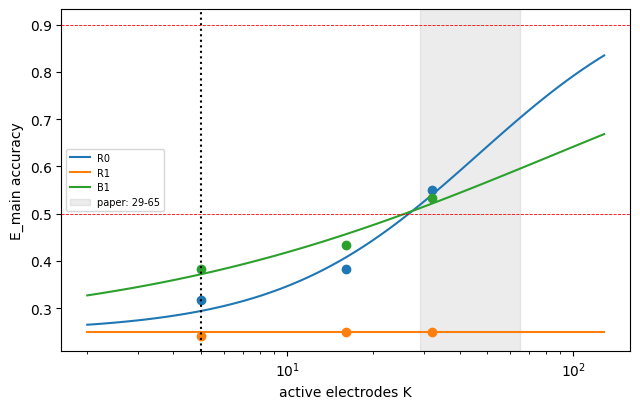

In [14]:
# ---------- 5. regression I: psychometric (logistic) curve of accuracy versus K -> K needed for 50 % and 90 % (hypothesis H1) ----------
GUESS = 1 / NC
def psy(x, m, b): return GUESS + (1 - GUESS) / (1 + np.exp(-b * (x - m)))
def fit_psy(xs, nc_, nt_):
    def nll(p): pr = np.clip(psy(xs, p[0], np.clip(p[1], .05, 20)), 1e-6, 1 - 1e-6); return -(nc_ * np.log(pr) + (nt_ - nc_) * np.log(1 - pr)).sum()
    best = min((minimize(nll, [m0, 1.], method="Nelder-Mead") for m0 in (xs.min() - 1, np.median(xs), xs.max() + 1)), key=lambda r: r.fun); return best.x[0], float(np.clip(best.x[1], .05, 20))
def k_at(m, b, p):
    s = (p - GUESS) / (1 - GUESS); return float(2 ** (m + np.log(s / (1 - s)) / b)) if 0 < s < 1 else np.nan
def fit_arm(a, idx): ks = np.array(Kset[a]); return fit_psy(np.log2(ks), np.array([corr[(a, K)][idx].sum() for K in ks]), np.full(len(ks), len(idx)))
def fmtK(x): return "n/a" if not np.isfinite(x) else (">10000" if x >= 1e4 else f"{x:.1f}")      # huge values mean the curve is flat
rng = np.random.default_rng(SEED); rows = []; fits = {}; nbp = 150 if QUICK else 500
for a in ARMS:
    if len(Kset[a]) < 2: continue
    m, b = fit_arm(a, np.arange(len(y))); fits[a] = (m, b); bs = np.array([[k_at(*fit_arm(a, rng.integers(0, len(y), len(y))), p) for p in (.5, .9)] for _ in range(nbp)])
    lo50, hi50, lo90, hi90 = (np.nanpercentile(bs[:, j], q) for j in (0, 1) for q in (2.5, 97.5)); k50, k90 = k_at(m, b, .5), k_at(m, b, .9); top = max(corr[(a, K)].mean() for K in Kset[a])
    note = "accuracy stays near chance on this K grid: the fit is not informative" if top - GUESS < .15 else ("outside the K grid: extrapolated" if not (min(Kset[a]) <= k90 <= max(Kset[a])) else "")
    rows.append(dict(arm=a, grid=str(Kset[a]), slope_per_doubling=b, K50=min(k50, 1e4), K50_CI=f"[{fmtK(lo50)}, {fmtK(hi50)}]", K90=min(k90, 1e4), K90_CI=f"[{fmtK(lo90)}, {fmtK(hi90)}]", note=note))
PSY = pd.DataFrame(rows); print("psychometric fit  accuracy = 1/NC + (1-1/NC) * sigmoid(slope * (log2 K - m)) , fitted by maximum likelihood; CIs by bootstrapping test images"); display(PSY.round(2)); PSY.to_csv(f"{OUT}/G_psychometric_s{SEED}.csv", index=False)
plt.figure(figsize=(6.5, 4.2)); xs_ = np.linspace(1, 7, 100)
for a, (m, b) in fits.items():
    l, = plt.plot(2 ** xs_, psy(xs_, m, b), "-", label=a); plt.plot(Kset[a], [corr[(a, K)].mean() for K in Kset[a]], "o", c=l.get_color())
plt.axvspan(29, 65, color="gray", alpha=.15, label="paper: 29-65"); plt.axvline(5, ls=":", c="k"); plt.axhline(.9, ls="--", c="r", lw=.6); plt.axhline(.5, ls="--", c="r", lw=.6); plt.xscale("log"); plt.xlabel("active electrodes K"); plt.ylabel("E_main accuracy"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(f"{OUT}/G_psychometric_s{SEED}.png", dpi=120); plt.show()


### 6. Regression II: odds ratios; accuracy versus fidelity

pooled logistic regression: correct ~ log2(K) + planner (reference = R1). Odds ratio > 1 = more likely to be recognised than random electrodes at the same K


,coef,odds_ratio,OR_lo,OR_hi
log2K,0.208,1.232,1.120,1.371
R0,0.786,2.194,1.844,2.650
B1,0.923,2.518,2.009,3.263
B2a,1.080,2.944,2.484,3.476
B2b,1.080,2.944,2.172,4.041



linear regression accuracy ~ contour F-score over 11 planner x K points: slope 0.27, R2 0.44, p 0.0251 | Spearman rho 0.74 (p 0.00968)
multiple regression acc ~ F + visible phosphenes (z-scored): coefficients {'F': 0.074, 'vis': 0.003}, R2 0.45


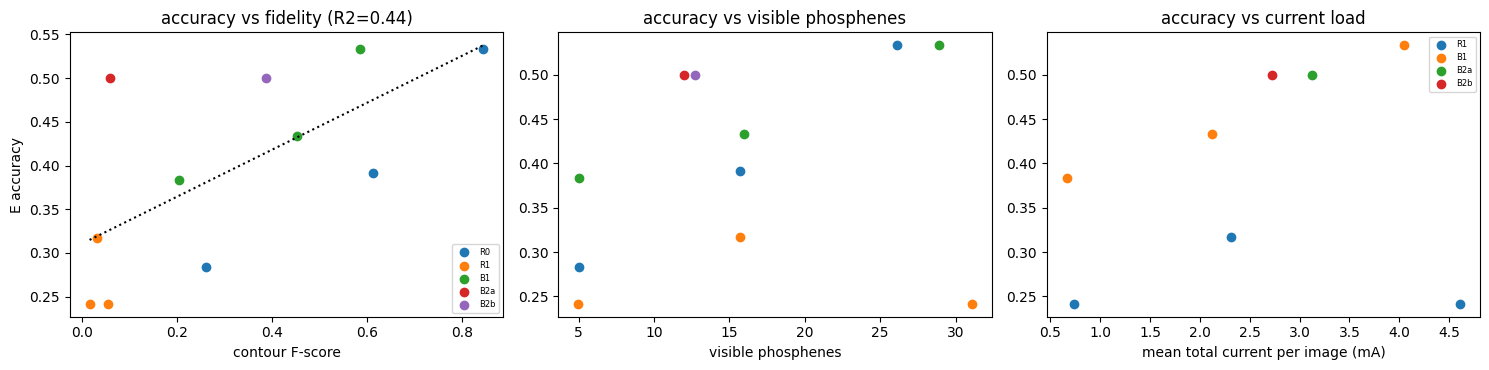

In [15]:
# ---------- 6. regression II: pooled logistic regression (odds ratio of each planner vs random electrodes, controlling for K) ----------
arms_p = [a for a in ARMS if Kset[a]]; ref = "R1"
def design(idx):
    X, Y = [], []
    for a in arms_p:
        for K in Kset[a]:
            row = [np.log2(K)] + [float(a == b) for b in arms_p if b != ref]; X.append(np.tile(row, (len(idx), 1))); Y.append(corr[(a, K)][idx].astype(int))
    return np.vstack(X), np.concatenate(Y)
cols = ["log2K"] + [b for b in arms_p if b != ref]; X, Y = design(np.arange(len(y))); lm = LogisticRegression(C=1e6, max_iter=2000).fit(X, Y)
bs = np.array([LogisticRegression(C=1e6, max_iter=2000).fit(*design(rng.integers(0, len(y), len(y)))).coef_[0] for _ in range(60 if QUICK else 200)])
OR = pd.DataFrame(dict(coef=lm.coef_[0], odds_ratio=np.exp(lm.coef_[0]), OR_lo=np.exp(np.percentile(bs, 2.5, 0)), OR_hi=np.exp(np.percentile(bs, 97.5, 0))), index=cols)
print(f"pooled logistic regression: correct ~ log2(K) + planner (reference = {ref}). Odds ratio > 1 = more likely to be recognised than random electrodes at the same K"); display(OR.round(3)); OR.to_csv(f"{OUT}/G_odds_ratios_s{SEED}.csv")
# --- accuracy versus contour fidelity / visible phosphenes / current (linear regression over the planner x K grid of Experiment 1) ---
df1 = pd.DataFrame([dict(arm=k.split("|")[0], K=int(k.split("|")[1]), acc=v["acc"], F=v["F"], vis=v["vis"], cur=v["cur_mean"] if v["cur_mean"] else np.nan, charge=v["charge_mA"] if v["charge_mA"] else np.nan) for k, v in exp1.items()])
lg = stats.linregress(df1.F, df1.acc); rho = stats.spearmanr(df1.F, df1.acc); print(f"\nlinear regression accuracy ~ contour F-score over {len(df1)} planner x K points: slope {lg.slope:.2f}, R2 {lg.rvalue ** 2:.2f}, p {lg.pvalue:.3g} | Spearman rho {rho.correlation:.2f} (p {rho.pvalue:.3g})")
Z = df1[["F", "vis"]]; Z = (Z - Z.mean()) / Z.std().replace(0, 1); lm2 = LinearRegression().fit(Z, df1.acc); print(f"multiple regression acc ~ F + visible phosphenes (z-scored): coefficients {dict(zip(['F', 'vis'], [round(float(v), 3) for v in lm2.coef_]))}, R2 {lm2.score(Z, df1.acc):.2f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a in ARMS:
    d = df1[df1.arm == a]; ax[0].scatter(d.F, d.acc, label=a); ax[1].scatter(d.vis, d.acc, label=a)
xx = np.linspace(df1.F.min(), df1.F.max(), 20); ax[0].plot(xx, lg.intercept + lg.slope * xx, "k:"); ax[0].set_xlabel("contour F-score"); ax[0].set_ylabel("E accuracy"); ax[0].set_title(f"accuracy vs fidelity (R2={lg.rvalue ** 2:.2f})"); ax[0].legend(fontsize=6)
ax[1].set_xlabel("visible phosphenes"); ax[1].set_title("accuracy vs visible phosphenes")
for a in ("R1", "B1", "B2a", "B2b"):
    d = df1[df1.arm == a].dropna(subset=["charge"]); ax[2].scatter(d.charge, d.acc, label=a)
ax[2].set_xlabel("mean total current per image (mA)"); ax[2].set_title("accuracy vs current load"); ax[2].legend(fontsize=6); plt.tight_layout(); plt.savefig(f"{OUT}/G_regression_s{SEED}.png", dpi=110); plt.show()


### 7. Regression III: robustness slopes

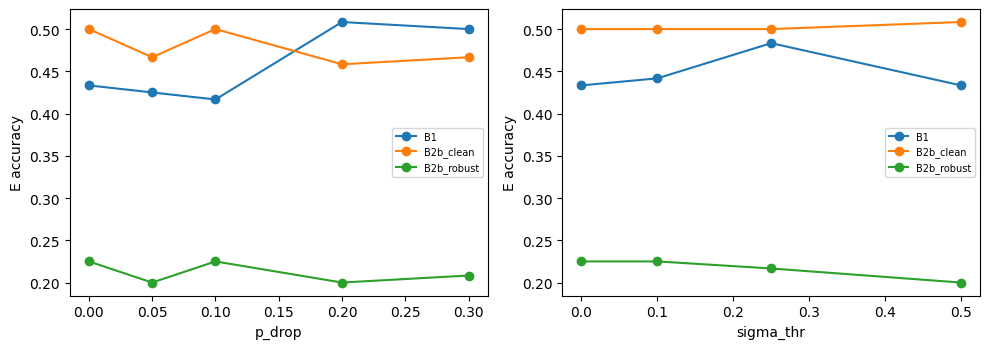

accuracy lost per +0.1 of noise (linear regression slope x 0.1) and share of clean accuracy retained at the strongest noise:


,noise,planner,acc_clean,acc_worst,slope_per_0p1,R2,retained
0,p_drop,B1,0.433,0.500,0.031,0.706,1.154
1,p_drop,B2b_clean,0.500,0.467,-0.010,0.375,0.933
2,p_drop,B2b_robust,0.225,0.208,-0.004,0.180,0.926
3,sigma_thr,B1,0.433,0.433,0.001,0.004,1.000
4,sigma_thr,B2b_clean,0.500,0.508,0.002,0.777,1.017
5,sigma_thr,B2b_robust,0.225,0.200,-0.005,0.952,0.889


In [16]:
# ---------- 7. regression III: robustness slopes (hypothesis H4) from Experiment 3 ----------
if exp3 is None: print("exp3 not found: run Module E first")
else:
    rows = []; fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    for a_, kind in zip(ax, ("p_drop", "sigma_thr")):
        lv = sorted({(0. if k == "p_drop|0.0" else float(k.split("|")[1])) for k in exp3 if k.startswith(kind) or k == "p_drop|0.0"})
        for pl in ("B1", "B2b_clean", "B2b_robust"):
            pts = [(l, exp3.get(f"{kind}|{l}", exp3.get("p_drop|0.0", {})).get(pl)) for l in lv]; pts = [(l, v) for l, v in pts if v is not None]
            if len(pts) < 3: continue
            x_, y_ = zip(*pts); r = stats.linregress(x_, y_); a_.plot(x_, y_, "o-", label=pl); rows.append(dict(noise=kind, planner=pl, acc_clean=y_[0], acc_worst=y_[-1], slope_per_0p1=r.slope * .1, R2=r.rvalue ** 2, retained=y_[-1] / max(y_[0], 1e-9)))
        a_.set_xlabel(kind); a_.set_ylabel("E accuracy"); a_.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{OUT}/G_robustness_s{SEED}.png", dpi=110); plt.show()
    print("accuracy lost per +0.1 of noise (linear regression slope x 0.1) and share of clean accuracy retained at the strongest noise:"); display(pd.DataFrame(rows).round(3))


### 8. Paired tests between planners

McNemar tests at K=16 (28 comparisons):


,A,B,A_right_B_wrong,A_wrong_B_right,p,p_Holm
0,R0,R1,19,3,0.0009,0.0180
1,R0,B1,5,11,0.2101,1.0000
2,R0,B2a,2,16,0.0013,0.0262
3,R0,B2b,11,25,0.0288,0.4034
4,R0,B2b:contour_only,35,23,0.1480,1.0000
5,R0,B2b:robust,45,26,0.0319,0.4151
6,R0,B2b:task_only,46,30,0.0846,1.0000
7,R1,B1,4,26,0.0001,0.0015
8,R1,B2a,2,32,0.0000,0.0000
9,R1,B2b,10,40,0.0000,0.0006


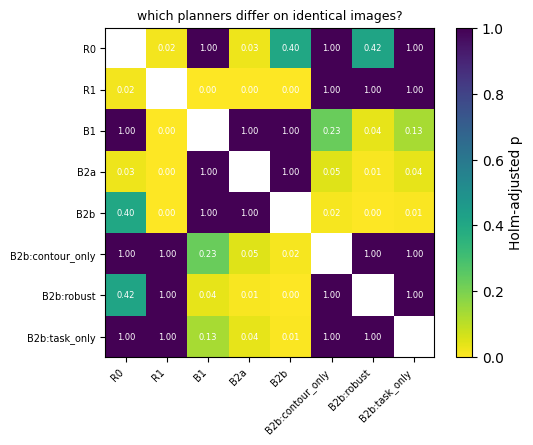

In [17]:
# ---------- 8. paired tests between planners at K = KB (exact McNemar, Holm-corrected) ----------
from scipy.stats import binomtest
names = [n for n, K in ITEMS if K == KB]; pairs = [(a, b) for i, a in enumerate(names) for b in names[i + 1:]]; res = []
for a, b in pairs:
    x1, x2 = corr[(a, KB)], corr[(b, KB)]; n01, n10 = int((x1 & ~x2).sum()), int((~x1 & x2).sum()); res.append([a, b, n01, n10, binomtest(min(n01, n10), n01 + n10, .5).pvalue if n01 + n10 else 1.])
order = np.argsort([r[4] for r in res]); adj = np.zeros(len(res)); run_max = 0.
for rank_, i in enumerate(order): run_max = max(run_max, (len(res) - rank_) * res[i][4]); adj[i] = min(1., run_max)
T = pd.DataFrame([dict(A=r[0], B=r[1], A_right_B_wrong=r[2], A_wrong_B_right=r[3], p=r[4], p_Holm=adj[i]) for i, r in enumerate(res)]); print(f"McNemar tests at K={KB} ({len(T)} comparisons):"); display(T.round(4)); T.to_csv(f"{OUT}/G_mcnemar_s{SEED}.csv", index=False)
M_ = pd.DataFrame(np.nan, index=names, columns=names)
for i, r in enumerate(res): M_.loc[r[0], r[1]] = M_.loc[r[1], r[0]] = adj[i]
plt.figure(figsize=(5.5, 4.5)); plt.imshow(M_.values.astype(float), cmap="viridis_r", vmin=0, vmax=1); plt.xticks(range(len(names)), names, rotation=45, ha="right", fontsize=7); plt.yticks(range(len(names)), names, fontsize=7); plt.colorbar(label="Holm-adjusted p")
for i in range(len(names)):
    for j in range(len(names)):
        if i != j: plt.text(j, i, f"{M_.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w")
plt.title("which planners differ on identical images?", fontsize=9); plt.tight_layout(); plt.show()


### 9. The trap

In [18]:
# ---------- 9. the trap (H3): does a task-only planner fool its own classifier but not the independent evaluator? ----------
rows = []
for v, nm in (("contour_only", "B2b:contour_only"), ("task_only", "B2b:task_only"), ("both", "B2b")):
    if (nm, KB) not in corr: continue
    pe = prob(nm, KB); r = dict(variant=v, E_acc=corr[(nm, KB)].mean(), E_macroF1=macro_f1_cm(cm_np(y, pe.argmax(1))), E_conf=pe.max(1).mean(), E_top_class_share=np.bincount(pe.argmax(1), minlength=NC).max() / len(y), visible=PR[f"vis|{nm}|{KB}"].mean())
    if f"tprob|{nm}|{KB}" in PR: pt = PR[f"tprob|{nm}|{KB}"]; r.update(Tc_acc=float((pt.argmax(1) == y).mean()), Tc_conf=float(pt.max(1).mean()))
    if exp4 and v in exp4: r["contour_F"] = exp4[v]["F"]
    r["gap_Tc_minus_E"] = r.get("Tc_acc", np.nan) - r["E_acc"]; rows.append(r)
TRAP = pd.DataFrame(rows).set_index("variant"); print(f"trap ablation at K={KB} (gap = how much the planner's own training classifier T_c overrates the pattern compared with the independent evaluator E):"); display(TRAP.round(3)); TRAP.to_csv(f"{OUT}/G_trap_s{SEED}.csv")
nm = "B2b:task_only"
if (nm, KB) in corr: print(f"\nwhat E sees for the task-only planner (rows = true class, columns = predicted):"); display(pd.DataFrame(cm_np(y, prob(nm, KB).argmax(1)), index=CLASSES, columns=CLASSES))
if probe: print("\nequivariance probe (ideal 1, fixed class code 0):", {k: (round(v, 2) if v is not None else None) for k, v in probe.items() if k != "n"})


trap ablation at K=16 (gap = how much the planner's own training classifier T_c overrates the pattern compared with the independent evaluator E):


,E_acc,E_macroF1,E_conf,E_top_class_share,visible,Tc_acc,Tc_conf,contour_F,gap_Tc_minus_E
variant,,,,,,,,,
contour_only,0.283,0.197,0.306,0.758,14.350,0.275,0.284,0.066,-0.008
task_only,0.250,0.100,0.300,1.000,12.992,0.250,0.321,0.005,0.000
both,0.500,0.424,0.386,0.358,12.733,0.358,0.400,0.387,-0.142



what E sees for the task-only planner (rows = true class, columns = predicted):


,circle,square,triangle,line
circle,0,0,30,0
square,0,0,30,0
triangle,0,0,30,0
line,0,0,30,0



equivariance probe (ideal 1, fixed class code 0): {'R0': 1.0, 'B1': 1.16, 'B2a': 0.0, 'B2b': 0.63}


### 10. Layout and electrode usage

phosphene size vs eccentricity (log-log regression): sigma ~ ecc^0.66, R2 0.98 | threshold vs eccentricity: Spearman 0.01
layout record: 500 electrodes, 498 usable, Dynaphos 0.1.3, I_max 200.0 uA

which electrodes does each planner drive at K=16? (usage-weighted averages over the test images)


,electrodes_ever_used,mean_ecc_deg,share_central_2p5deg,mean_threshold_uA,mean_phosphene_sigma_deg,usage_concentration_gini
planner,,,,,,
R1,493,2.356,0.587,89.228,0.040,0.260
B1,447,2.784,0.410,90.717,0.046,0.456
B2a,63,2.304,0.438,86.645,0.040,0.876
B2b,456,2.297,0.561,88.158,0.040,0.353
layout (usable),498,2.280,0.600,88.941,0.039,NaN


B1 vs B2b: Jaccard overlap of electrode sets 0.86 | Spearman correlation of usage counts 0.47


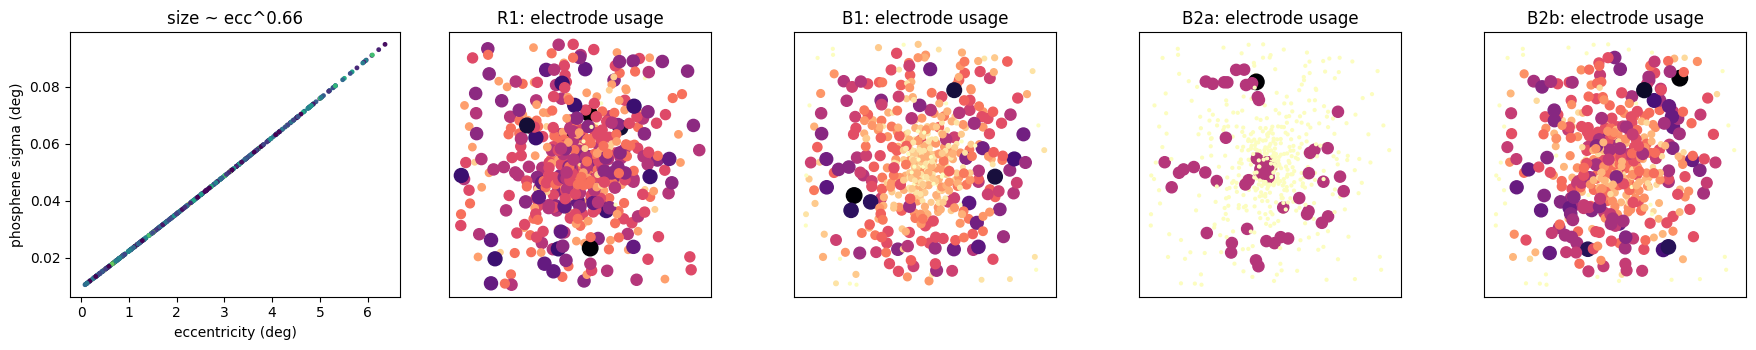

In [19]:
# ---------- 10. layout and electrode-usage analysis: does the learned planner exploit the electrode map? (H2) ----------
xy, thr_, sg = atlas["xy_deg"], atlas["thr_uA"], atlas["sigma_deg"]; ecc = np.linalg.norm(xy, axis=1); usable = atlas["usable"].astype(bool)
ok = ecc > .2; lgs = stats.linregress(np.log(ecc[ok]), np.log(sg[ok])); print(f"phosphene size vs eccentricity (log-log regression): sigma ~ ecc^{lgs.slope:.2f}, R2 {lgs.rvalue ** 2:.2f} | threshold vs eccentricity: Spearman {stats.spearmanr(ecc, thr_).correlation:.2f}")
if crec: print(f"layout record: {crec['n_elec_used']} electrodes, {crec['usable_electrodes']} usable, Dynaphos {crec['dynaphos_version']}, I_max {crec['I_max_uA']} uA")
use = {n: PR[f"usage|{n}|{KB}"].astype(float) for n in ("R1", "B1", "B2a", "B2b") if f"usage|{n}|{KB}" in PR}; rows = []
for n, u in use.items():
    s = u / u.sum(); rows.append(dict(planner=n, electrodes_ever_used=int((u > 0).sum()), mean_ecc_deg=float((s * ecc).sum()), share_central_2p5deg=float(s[ecc < 2.5].sum()), mean_threshold_uA=float((s * thr_).sum()),
                                      mean_phosphene_sigma_deg=float((s * sg).sum()), usage_concentration_gini=float(1 - 2 * np.sum(np.cumsum(np.sort(s)) / len(s)) + 1 / len(s))))
rows.append(dict(planner="layout (usable)", electrodes_ever_used=int(usable.sum()), mean_ecc_deg=float(ecc[usable].mean()), share_central_2p5deg=float((ecc[usable] < 2.5).mean()), mean_threshold_uA=float(thr_[usable].mean()), mean_phosphene_sigma_deg=float(sg[usable].mean())))
USE = pd.DataFrame(rows).set_index("planner"); print(f"\nwhich electrodes does each planner drive at K={KB}? (usage-weighted averages over the test images)"); display(USE.round(3)); USE.to_csv(f"{OUT}/G_usage_s{SEED}.csv")
if "B1" in use and "B2b" in use:
    a_, b_ = use["B1"] > 0, use["B2b"] > 0; print(f"B1 vs B2b: Jaccard overlap of electrode sets {np.sum(a_ & b_) / max(np.sum(a_ | b_), 1):.2f} | Spearman correlation of usage counts {stats.spearmanr(use['B1'], use['B2b']).correlation:.2f}")
fig, ax = plt.subplots(1, len(use) + 1, figsize=(3.6 * (len(use) + 1), 3.6))
ax[0].scatter(ecc, sg, s=6, c=thr_, cmap="viridis"); ax[0].set_xlabel("eccentricity (deg)"); ax[0].set_ylabel("phosphene sigma (deg)"); ax[0].set_title(f"size ~ ecc^{lgs.slope:.2f}")
for a_, (n, u) in zip(ax[1:], use.items()): sc_ = a_.scatter(xy[:, 0], xy[:, 1], s=4 + 120 * u / max(u.max(), 1), c=u, cmap="magma_r"); a_.set_aspect("equal"); a_.set_title(f"{n}: electrode usage"); a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.savefig(f"{OUT}/G_usage_s{SEED}.png", dpi=110); plt.show()


### 11. Hypotheses at a glance

In [20]:
# ---------- 11. what the data say about H1-H4 (numbers only; read them with the caveats of the project plan, section 2) ----------
print("H1 capacity: K needed for 50% / 90% E accuracy (psychometric fit; CIs in the table above)")
for _, r in PSY.iterrows(): print(f"   {r['arm']:3s} K50 {fmtK(r['K50'])} {r['K50_CI']}   K90 {fmtK(r['K90'])} {r['K90_CI']}   {r['note']}")
print(f"\nH2 learned vs heuristic planner at matched K (E accuracy, contour F-score):")
for K in K_B2B:
    if f"B1|{K}" in exp1 and f"B2b|{K}" in exp1:
        b1, b2 = exp1[f"B1|{K}"], exp1[f"B2b|{K}"]; p_ = T[((T.A == "B1") & (T.B == "B2b")) | ((T.A == "B2b") & (T.B == "B1"))].p_Holm.values if K == KB else []
        print(f"   K={K}: B1 acc {b1['acc']:.3f} F {b1['F']:.2f} | B2b acc {b2['acc']:.3f} F {b2['F']:.2f} | acc difference {b2['acc'] - b1['acc']:+.3f}" + (f" (McNemar Holm p = {p_[0]:.3f})" if len(p_) else ""))
print("\nH3 the trap (E accuracy, T_c accuracy, contour F):")
for v, r in TRAP.iterrows(): print(f"   {v:13s} E {r['E_acc']:.3f} | T_c {r.get('Tc_acc', np.nan):.3f} | F {r.get('contour_F', np.nan):.2f} | top-class share {r['E_top_class_share']:.2f}")
print("\nH4 robustness: see the slope table above (accuracy lost per +0.1 noise; compare B2b_clean with B2b_robust)")
print(f"\nCAUTION: the evaluator E_main itself reaches {clf_acc(E, Xbv, ybv).mean():.0%} on held-out random-dot images (chance = {1 / NC:.0%}); if that is low, every accuracy above is limited by E, not by the planners.\n{len(y)} test images and {crec['n_elec_used'] if crec else '?'} electrodes, QUICK={QUICK}. With QUICK=True the K grid has only {len(K_LIST)} points and the planners trained for {STEPS} steps, so treat curve fits and p-values as a smoke test; set QUICK=False in Modules B, C and E for the real run.")
json.dump(dict(psychometric=PSY.to_dict("records"), odds_ratios=OR.reset_index().to_dict("records"), trap=TRAP.reset_index().to_dict("records"), usage=USE.reset_index().to_dict("records"), QUICK=QUICK, n_test=int(len(y))), open(f"{OUT}/G_summary_s{SEED}.json", "w"), indent=1, default=float)
print("saved tables and figures (G_*) in", OUT)


H1 capacity: K needed for 50% / 90% E accuracy (psychometric fit; CIs in the table above)
   R0  K50 26.6 [19.1, 53.3]   K90 208.6 [80.4, 7581.7]   outside the K grid: extrapolated
   R1  K50 >10000 [38.6, >10000]   K90 >10000 [53.2, >10000]   accuracy stays near chance on this K grid: the fit is not informative
   B1  K50 25.9 [12.7, 1364.2]   K90 2190.1 [208.1, >10000]   outside the K grid: extrapolated

H2 learned vs heuristic planner at matched K (E accuracy, contour F-score):
   K=16: B1 acc 0.433 F 0.45 | B2b acc 0.500 F 0.39 | acc difference +0.067 (McNemar Holm p = 1.000)

H3 the trap (E accuracy, T_c accuracy, contour F):
   contour_only  E 0.283 | T_c 0.275 | F 0.07 | top-class share 0.76
   task_only     E 0.250 | T_c 0.250 | F 0.00 | top-class share 1.00
   both          E 0.500 | T_c 0.358 | F 0.39 | top-class share 0.36

H4 robustness: see the slope table above (accuracy lost per +0.1 noise; compare B2b_clean with B2b_robust)

CAUTION: the evaluator E_main itself reaches 